In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Load dataset
df = pd.read_csv("ecommerce_logistics_week2.csv")

# Convert order date to datetime
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

# Create folder for visualizations
output_dir = Path("Images")
output_dir.mkdir(exist_ok=True)

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Unique order IDs:", df["Order_ID"].nunique())

display(df.head())

Dataset loaded successfully
Rows: 71
Columns: 15
Unique order IDs: 70


,Order_ID,Order_Date,Customer_ID,Product_Category,Order_Value,Shipping_Cost,Warehouse,Delivery_Partner,Delivery_Days,Expected_Days,Order_Status,Customer_Rating,Return_Flag,Inventory_Level,Reorder_Level
0,ORD1001,2026-01-02,CUST001,Electronics,45000,650.0,Bangalore,Delivery,3,4,Delivered,5,No,25.0,20
1,ORD1002,2026-01-03,CUST002,Fashion,2500,180.0,Mumbai,BlueDart,2,3,Delivered,4,No,10.0,15
2,ORD1003,2026-01-04,CUST003,Home & Kitchen,7800,320.0,Delhi,Ecom Express,5,4,Delivered,3,No,30.0,20
3,ORD1004,2026-01-05,CUST004,Beauty,1500,120.0,Bangalore,Delivery,2,3,Delivered,5,No,8.0,10
4,ORD1005,2026-01-06,CUST005,Electronics,32000,550.0,Hyderabad,BlueDart,4,4,Delivered,4,No,50.0,25


In [12]:
# Missing values
import pandas as pd
import numpy as np
df = pd.read_csv("ecommerce_logistics_week2.csv")
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print("MISSING VALUE REPORT")
display(missing_report[missing_report["Missing_Count"] > 0])


# Duplicate records
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df["Order_ID"].duplicated().sum())

display(
    df[df["Order_ID"].duplicated(keep=False)]
    .sort_values("Order_ID")
)

# Invalid or unusual records
print("Negative order values:")
display(df[df["Order_Value"] < 0])

print("Zero or negative delivery days:")
display(df[df["Delivery_Days"] <= 0])

print("Shipping costs above 5,000:")
display(df[df["Shipping_Cost"] > 5000])

print("Late deliveries:")
display(
    df[df["Delivery_Days"] > df["Expected_Days"]][
        ["Order_ID", "Delivery_Partner",
         "Delivery_Days", "Expected_Days"]
    ])


MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
Shipping_Cost,1,1.41
Inventory_Level,1,1.41


Exact duplicate rows: 1
Duplicate order IDs: 1


,Order_ID,Order_Date,Customer_ID,Product_Category,Order_Value,Shipping_Cost,Warehouse,Delivery_Partner,Delivery_Days,Expected_Days,Order_Status,Customer_Rating,Return_Flag,Inventory_Level,Reorder_Level
1,ORD1002,2026-01-03,CUST002,Fashion,2500,180.0,Mumbai,BlueDart,2,3,Delivered,4,No,10.0,15
30,ORD1002,2026-01-03,CUST002,Fashion,2500,180.0,Mumbai,BlueDart,2,3,Delivered,4,No,10.0,15


Negative order values:


...

,Order_ID,Order_Date,Customer_ID,Product_Category,Order_Value,Shipping_Cost,Warehouse,Delivery_Partner,Delivery_Days,Expected_Days,Order_Status,Customer_Rating,Return_Flag,Inventory_Level,Reorder_Level
32,ORD1032,2026-02-02,CUST032,Fashion,3600,190.0,Chennai,Ecom Express,0,3,Delivered,4,No,14.0,19
41,ORD1041,2026-02-11,CUST041,Electronics,27500,500.0,Hyderabad,Delivery,-2,4,Delivered,3,No,18.0,12


Shipping costs above 5,000:


,Order_ID,Order_Date,Customer_ID,Product_Category,Order_Value,Shipping_Cost,Warehouse,Delivery_Partner,Delivery_Days,Expected_Days,Order_Status,Customer_Rating,Return_Flag,Inventory_Level,Reorder_Level
31,ORD1031,2026-02-01,CUST031,Electronics,18500,25000.0,Bangalore,Delivery,3,4,Delivered,5,No,22.0,20


Late deliveries:


,Order_ID,Delivery_Partner,Delivery_Days,Expected_Days
2,ORD1003,Ecom Express,5,4
5,ORD1006,Ecom Express,6,5
8,ORD1009,Ecom Express,7,5
11,ORD1012,Ecom Express,5,4
12,ORD1013,Delivery,4,3
16,ORD1017,Delivery,4,3
20,ORD1021,Ecom Express,6,5
23,ORD1024,Ecom Express,5,4
28,ORD1029,BlueDart,5,4
43,ORD1043,Ecom Express,4,3


In [5]:
# Preserve df unchanged for data-quality reporting.
analysis = df.drop_duplicates(
    subset="Order_ID", keep="first"
).copy()

# Do not treat invalid delivery durations as valid measurements.
analysis["Delivery_Days_Valid"] = (
    analysis["Delivery_Days"].where(
        analysis["Delivery_Days"] > 0
    )
)

# Mark late deliveries using positive delivery durations.
analysis["Late"] = (
    analysis["Delivery_Days_Valid"]
    > analysis["Expected_Days"]
)

# Flag records at or below the reorder threshold.
analysis["Reorder_Alert"] = (
    analysis["Inventory_Level"]
    <= analysis["Reorder_Level"]
)

# Actual recorded stockout indicator.
analysis["Stockout"] = (
    analysis["Inventory_Level"] <= 0
)

print("Original records:", len(df))
print("Records after duplicate-ID removal:", len(analysis))
print("Unique orders:", analysis["Order_ID"].nunique())


Original records: 71
Records after duplicate-ID removal: 70
Unique orders: 70


In [6]:
numeric_columns = [
    "Order_Value",
    "Shipping_Cost",
    "Delivery_Days_Valid",
    "Expected_Days",
    "Customer_Rating",
    "Inventory_Level",
    "Reorder_Level"
]

print("DESCRIPTIVE STATISTICS")
display(analysis[numeric_columns].describe().round(2))

print("Median values")
display(analysis[numeric_columns].median().round(2))

print("Missing values in analysis dataset")
display(
    analysis.isnull().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

DESCRIPTIVE STATISTICS


,Order_Value,Shipping_Cost,Delivery_Days_Valid,Expected_Days,Customer_Rating,Inventory_Level,Reorder_Level
count,70.00,69.00,68.00,70.00,70.00,69.00,70.00
mean,12547.14,666.81,3.35,3.54,4.04,29.87,31.56
std,14483.83,2977.92,1.32,0.93,0.97,17.29,17.41
min,-500.00,110.00,1.00,2.00,2.00,8.00,6.00
25%,2725.00,150.00,2.00,3.00,4.00,17.00,19.00
50%,5600.00,220.00,3.00,4.00,4.00,27.00,25.50
75%,18500.00,480.00,4.00,4.00,5.00,45.00,43.00
max,52000.00,25000.00,7.00,5.00,5.00,80.00,80.00


Median values


Order_Value            5600.0
Shipping_Cost           220.0
Delivery_Days_Valid       3.0
Expected_Days             4.0
Customer_Rating           4.0
Inventory_Level          27.0
Reorder_Level            25.5
dtype: float64

Missing values in analysis dataset


,Missing_Count
Shipping_Cost,1
Inventory_Level,1
Delivery_Days_Valid,2


PRODUCT CATEGORY ANALYSIS


,Order_Count,Total_Order_Value,Average_Order_Value
Product_Category,,,
Electronics,19,643500,33868.42
Fashion,19,83400,4389.47
Grocery,11,27900,2536.36
Home & Kitchen,11,104400,9490.91
Beauty,10,19100,1910.00


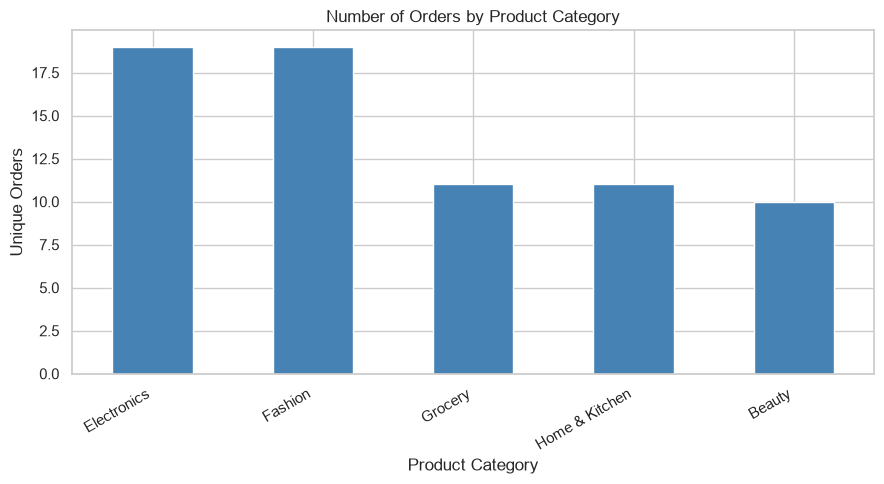

In [7]:
category_demand = analysis.groupby(
    "Product_Category"
).agg(
    Order_Count=("Order_ID", "nunique"),
    Total_Order_Value=("Order_Value", "sum"),
    Average_Order_Value=("Order_Value", "mean")
).sort_values("Order_Count", ascending=False)

print("PRODUCT CATEGORY ANALYSIS")
display(category_demand.round(2))

category_demand["Order_Count"].plot(
    kind="bar", color="steelblue"
)

plt.title("Number of Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Unique Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "01_product_demand.png", dpi=300)
plt.show()


TOTAL RECORDED ORDER VALUE BY CATEGORY


,Total_Order_Value
Product_Category,
Electronics,643500
Home & Kitchen,104400
Fashion,83400
Grocery,27900
Beauty,19100


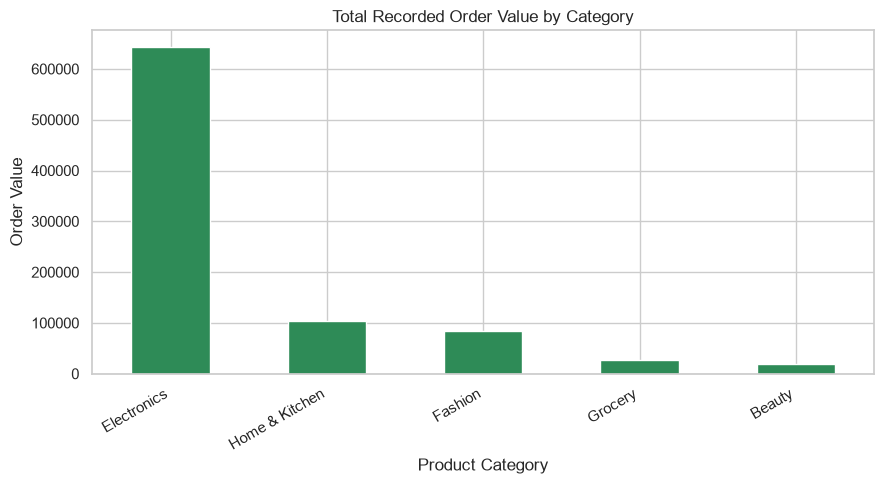

Total recorded order value: 878300


In [8]:
category_sales = (
    analysis.groupby("Product_Category")["Order_Value"]
    .sum()
    .sort_values(ascending=False)
)

print("TOTAL RECORDED ORDER VALUE BY CATEGORY")
display(category_sales.to_frame("Total_Order_Value").round(2))

category_sales.plot(
    kind="bar", color="seagreen"
)

plt.title("Total Recorded Order Value by Category")
plt.xlabel("Product Category")
plt.ylabel("Order Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "02_sales_by_category.png", dpi=300)
plt.show()

print(
    "Total recorded order value:",
    round(analysis["Order_Value"].sum(), 2)
)

WAREHOUSE INVENTORY ANALYSIS


,Average_Inventory,Average_Reorder_Level,Number_of_Records,Reorder_Alerts,Stockout_Records,Reorder_Alert_Rate_Pct
Warehouse,,,,,,
Bangalore,28.76,29.00,17,9,0,52.94
Chennai,27.67,25.33,12,7,0,58.33
Delhi,37.93,38.73,15,11,0,73.33
Hyderabad,28.58,32.00,12,8,0,66.67
Mumbai,25.23,32.46,13,12,0,92.31


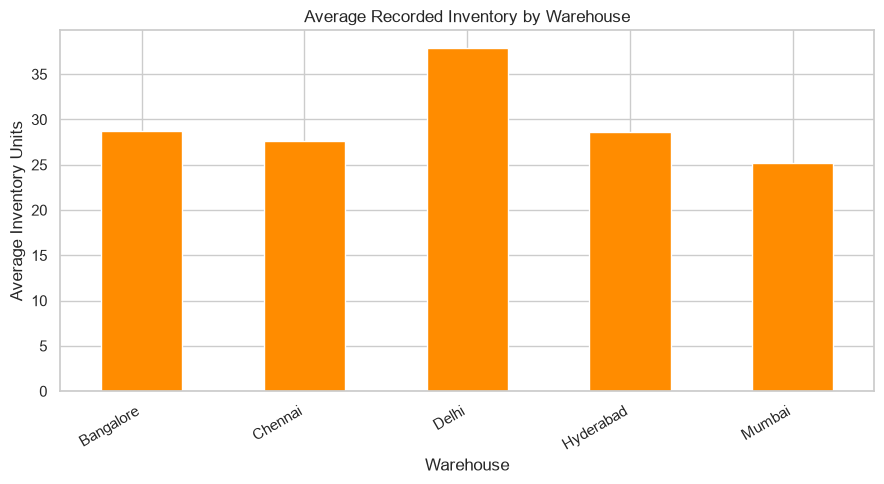

In [9]:
inventory = analysis.dropna(
    subset=["Inventory_Level", "Reorder_Level"]
).copy()

warehouse_summary = inventory.groupby("Warehouse").agg(
    Average_Inventory=("Inventory_Level", "mean"),
    Average_Reorder_Level=("Reorder_Level", "mean"),
    Number_of_Records=("Order_ID", "nunique"),
    Reorder_Alerts=("Reorder_Alert", "sum"),
    Stockout_Records=("Stockout", "sum")
)

warehouse_summary["Reorder_Alert_Rate_Pct"] = (
    inventory.groupby("Warehouse")["Reorder_Alert"].mean() * 100
)

print("WAREHOUSE INVENTORY ANALYSIS")
display(warehouse_summary.round(2))

warehouse_summary["Average_Inventory"].plot(
    kind="bar", color="darkorange"
)

plt.title("Average Recorded Inventory by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Average Inventory Units")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "03_warehouse_inventory.png", dpi=300)
plt.show()

Records at or below reorder level: 47
Reorder alert rate (%): 68.12
Records with zero or negative inventory: 0
Recorded stockout rate (%): 0.0
REORDER ALERT RATE BY WAREHOUSE (%)


Warehouse
Mumbai       92.31
Delhi        73.33
Hyderabad    66.67
Chennai      58.33
Bangalore    52.94
Name: Reorder_Alert, dtype: float64

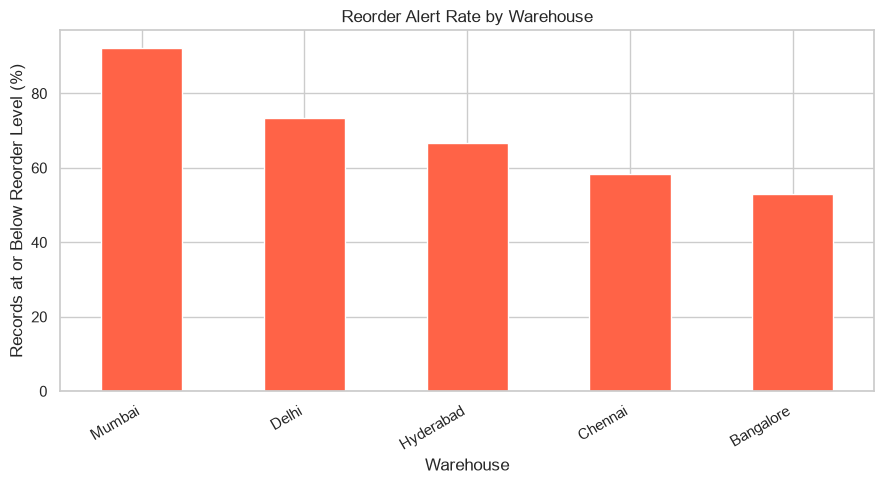

In [10]:
print(
    "Records at or below reorder level:",
    int(inventory["Reorder_Alert"].sum())
)

print(
    "Reorder alert rate (%):",
    round(inventory["Reorder_Alert"].mean() * 100, 2)
)

print(
    "Records with zero or negative inventory:",
    int(inventory["Stockout"].sum())
)

print(
    "Recorded stockout rate (%):",
    round(inventory["Stockout"].mean() * 100, 2)
)

alert_by_warehouse = (
    inventory.groupby("Warehouse")["Reorder_Alert"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("REORDER ALERT RATE BY WAREHOUSE (%)")
display(alert_by_warehouse.round(2))

alert_by_warehouse.plot(
    kind="bar", color="tomato"
)

plt.title("Reorder Alert Rate by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Records at or Below Reorder Level (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "04_reorder_alerts.png", dpi=300)
plt.show()

DELIVERY PARTNER PERFORMANCE


,Shipment_Count,Average_Delivery_Days,Median_Delivery_Days,Late_Shipments,Late_Rate,Late_Rate_Pct
Delivery_Partner,,,,,,
BlueDart,23,3.04,3.0,3,0.13,13.04
Delivery,22,2.73,2.5,3,0.14,13.64
Ecom Express,23,4.26,4.0,9,0.39,39.13


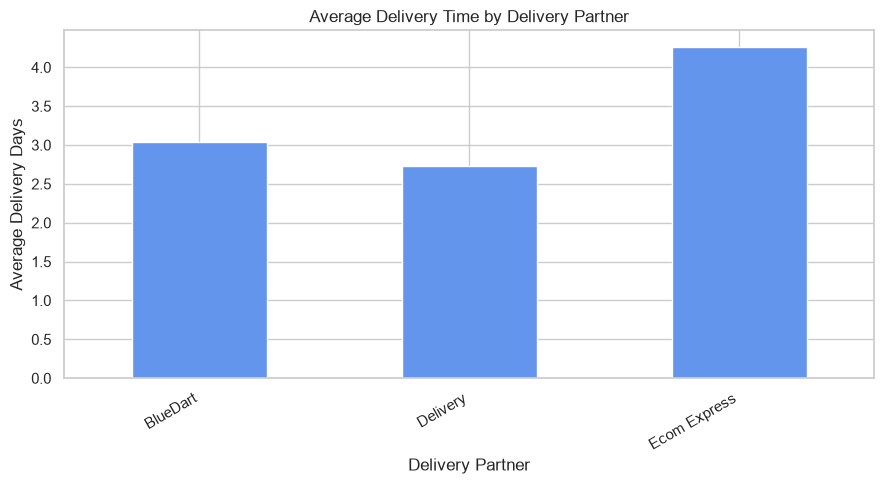

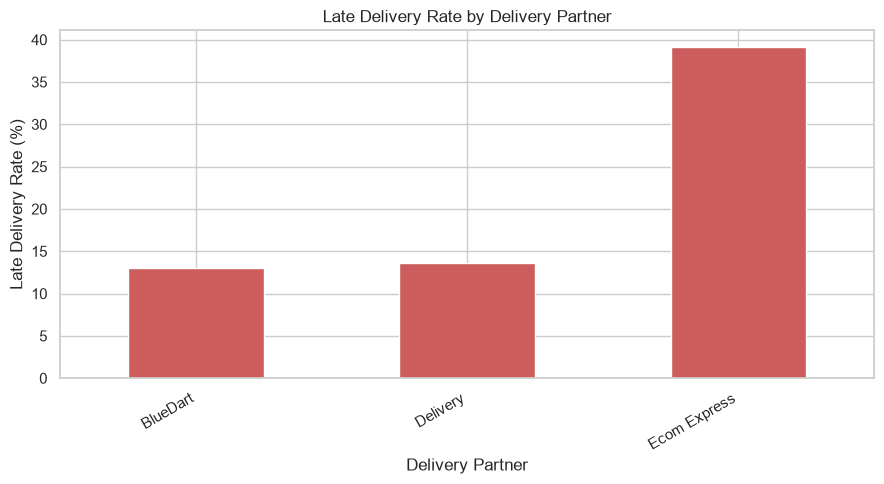

In [11]:
delivery = analysis.dropna(
    subset=["Delivery_Days_Valid", "Expected_Days",
            "Delivery_Partner"]
).copy()

delivery["Late"] = (
    delivery["Delivery_Days_Valid"] > delivery["Expected_Days"]
)

delivery_summary = delivery.groupby(
    "Delivery_Partner"
).agg(
    Shipment_Count=("Order_ID", "nunique"),
    Average_Delivery_Days=("Delivery_Days_Valid", "mean"),
    Median_Delivery_Days=("Delivery_Days_Valid", "median"),
    Late_Shipments=("Late", "sum"),
    Late_Rate=("Late", "mean")
)

delivery_summary["Late_Rate_Pct"] = (
    delivery_summary["Late_Rate"] * 100
)

print("DELIVERY PARTNER PERFORMANCE")
display(delivery_summary.round(2))

delivery_summary["Average_Delivery_Days"].plot(
    kind="bar", color="cornflowerblue"
)

plt.title("Average Delivery Time by Delivery Partner")
plt.xlabel("Delivery Partner")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "05_delivery_performance.png", dpi=300)
plt.show()

delivery_summary["Late_Rate_Pct"].plot(
    kind="bar", color="indianred"
)

plt.title("Late Delivery Rate by Delivery Partner")
plt.xlabel("Delivery Partner")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "06_late_delivery_rate.png", dpi=300)
plt.show()

SHIPPING COST SUMMARY


,Shipment_Count,Average_Shipping_Cost,Median_Shipping_Cost,Total_Shipping_Cost
Delivery_Partner,,,,
BlueDart,23,331.09,210.0,7615.0
Delivery,23,1330.00,190.0,30590.0
Ecom Express,23,339.35,350.0,7805.0


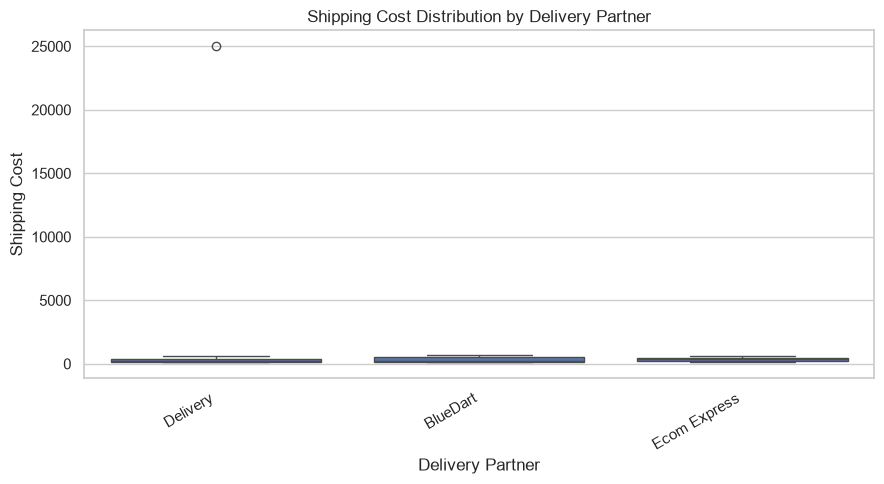

POTENTIAL SHIPPING COST OUTLIERS


,Order_ID,Shipping_Cost,Delivery_Partner
31,ORD1031,25000.0,Delivery


In [12]:
cost_data = analysis.dropna(
    subset=["Shipping_Cost", "Delivery_Partner"]
).copy()

cost_summary = cost_data.groupby("Delivery_Partner").agg(
    Shipment_Count=("Order_ID", "count"),
    Average_Shipping_Cost=("Shipping_Cost", "mean"),
    Median_Shipping_Cost=("Shipping_Cost", "median"),
    Total_Shipping_Cost=("Shipping_Cost", "sum")
)

print("SHIPPING COST SUMMARY")
display(cost_summary.round(2))

sns.boxplot(
    data=cost_data,
    x="Delivery_Partner",
    y="Shipping_Cost"
)

plt.title("Shipping Cost Distribution by Delivery Partner")
plt.xlabel("Delivery Partner")
plt.ylabel("Shipping Cost")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "07_shipping_cost_distribution.png", dpi=300)
plt.show()

# IQR-based outlier investigation
cost = cost_data["Shipping_Cost"]
q1 = cost.quantile(0.25)
q3 = cost.quantile(0.75)
iqr = q3 - q1

outliers = cost_data[
    (cost_data["Shipping_Cost"] < q1 - 1.5 * iqr)
    | (cost_data["Shipping_Cost"] > q3 + 1.5 * iqr)
]

print("POTENTIAL SHIPPING COST OUTLIERS")
display(
    outliers[["Order_ID", "Shipping_Cost", "Delivery_Partner"]]
)

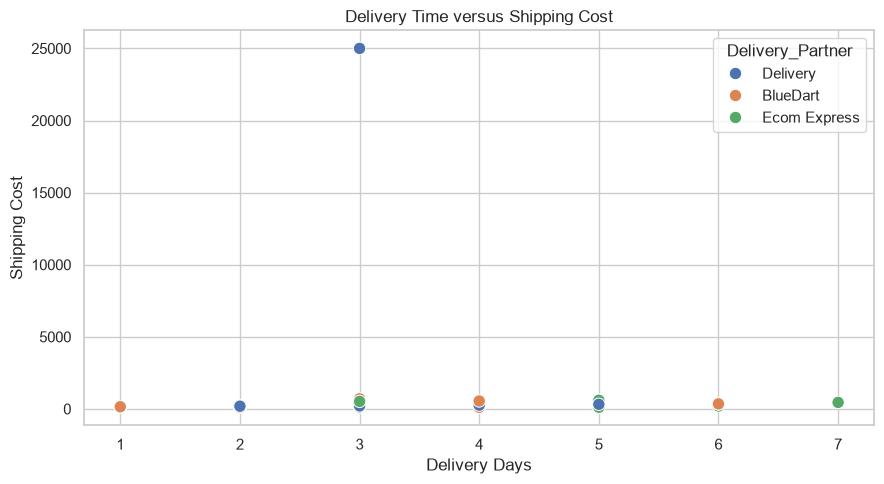

Delivery time and shipping cost correlation: -0.014


In [13]:
relationship_data = analysis.dropna(
    subset=["Delivery_Days_Valid", "Shipping_Cost",
            "Delivery_Partner"]
)

sns.scatterplot(
    data=relationship_data,
    x="Delivery_Days_Valid",
    y="Shipping_Cost",
    hue="Delivery_Partner",
    s=80
)

plt.title("Delivery Time versus Shipping Cost")
plt.xlabel("Delivery Days")
plt.ylabel("Shipping Cost")
plt.tight_layout()
plt.savefig(output_dir / "08_delivery_vs_shipping_cost.png", dpi=300)
plt.show()

correlation = relationship_data[
    ["Delivery_Days_Valid", "Shipping_Cost"]
].corr().iloc[0, 1]

print("Delivery time and shipping cost correlation:",
      round(correlation, 3))

MONTHLY RECORDED ORDER VALUE


,Order_Value
Order_Date,
2026-01,370400
2026-02,317700
2026-03,190200


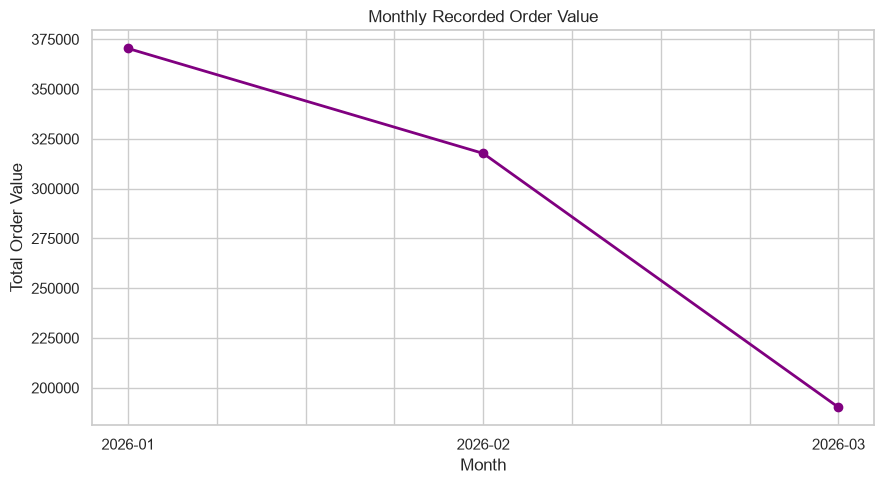

In [14]:
monthly_order_value = (
    analysis.dropna(subset=["Order_Date"])
    .groupby(analysis["Order_Date"].dt.to_period("M"))["Order_Value"]
    .sum()
)

print("MONTHLY RECORDED ORDER VALUE")
display(monthly_order_value.to_frame("Order_Value"))

monthly_order_value.index = monthly_order_value.index.astype(str)

monthly_order_value.plot(
    marker="o", linewidth=2, color="purple"
)

plt.title("Monthly Recorded Order Value")
plt.xlabel("Month")
plt.ylabel("Total Order Value")
plt.tight_layout()
plt.savefig(output_dir / "09_monthly_order_value.png", dpi=300)
plt.show()


CORRELATION MATRIX


,Order_Value,Shipping_Cost,Delivery_Days_Valid,Expected_Days,Customer_Rating,Inventory_Level,Reorder_Level
Order_Value,1.00,0.11,0.21,0.32,0.15,-0.04,-0.03
Shipping_Cost,0.11,1.00,-0.01,0.09,0.13,-0.05,-0.07
Delivery_Days_Valid,0.21,-0.01,1.00,0.79,-0.74,0.16,0.14
Expected_Days,0.32,0.09,0.79,1.00,-0.43,0.13,0.12
Customer_Rating,0.15,0.13,-0.74,-0.43,1.00,-0.03,0.00
Inventory_Level,-0.04,-0.05,0.16,0.13,-0.03,1.00,0.75
Reorder_Level,-0.03,-0.07,0.14,0.12,0.00,0.75,1.00


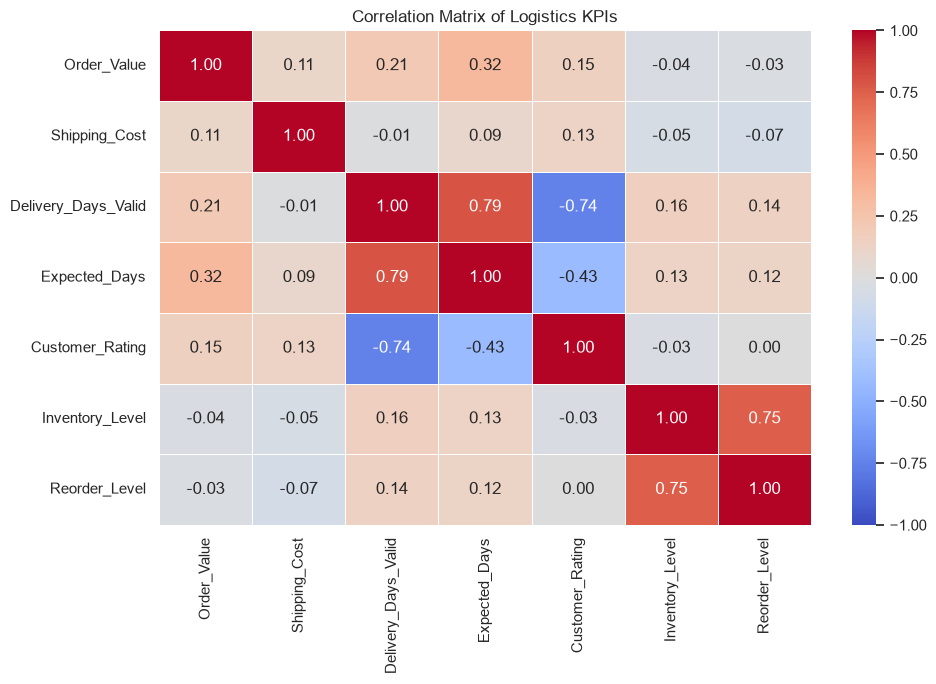

In [15]:
correlation_columns = [
    "Order_Value",
    "Shipping_Cost",
    "Delivery_Days_Valid",
    "Expected_Days",
    "Customer_Rating",
    "Inventory_Level",
    "Reorder_Level"
]

correlation_matrix = analysis[
    correlation_columns
].corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Logistics KPIs")
plt.tight_layout()
plt.savefig(output_dir / "10_correlation_heatmap.png", dpi=300)
plt.show()

In [16]:
late_rate = delivery["Late"].mean() * 100

kpis = pd.DataFrame({
    "Metric": [
        "Unique Orders",
        "Total Recorded Order Value",
        "Average Shipping Cost",
        "Average Positive Delivery Days",
        "Late Delivery Rate (%)",
        "Average Customer Rating",
        "Reorder Alert Rate (%)",
        "Recorded Stockout Rate (%)"
    ],
    "Value": [
        analysis["Order_ID"].nunique(),
        analysis["Order_Value"].sum(),
        analysis["Shipping_Cost"].mean(),
        analysis["Delivery_Days_Valid"].mean(),
        late_rate,
        analysis["Customer_Rating"].mean(),
        inventory["Reorder_Alert"].mean() * 100,
        inventory["Stockout"].mean() * 100
    ]
})

print("WEEK 3 LOGISTICS KPI SUMMARY")
display(kpis.round(2))

kpis.to_csv(output_dir / "week3_kpi_summary.csv", index=False)

print("Charts and KPI summary saved in:", output_dir.resolve())

WEEK 3 LOGISTICS KPI SUMMARY


,Metric,Value
0,Unique Orders,70.00
1,Total Recorded Order Value,878300.00
2,Average Shipping Cost,666.81
3,Average Positive Delivery Days,3.35
4,Late Delivery Rate (%),22.06
5,Average Customer Rating,4.04
6,Reorder Alert Rate (%),68.12
7,Recorded Stockout Rate (%),0.00


Charts and KPI summary saved in: C:\Users\sankari\Desktop\Important\Week_1_Power_BI_Data_Analysts\Week_3_Strategic_Planning_Report\Images
